In [1]:
!pip install -q datasets huggingface_hub

In [3]:
from huggingface_hub import snapshot_download

local_dir = snapshot_download(
    repo_id="kriyam-ai/kriyam-tamperflow",
    repo_type="dataset",
    force_download=True,
    max_workers=4
)

print("Downloaded to:", local_dir)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4229 files:   0%|          | 0/4229 [00:00<?, ?it/s]

Downloaded to: /root/.cache/huggingface/hub/datasets--kriyam-ai--kriyam-tamperflow/snapshots/281155b75f62ea0db538dcff38d06109be58e912


In [6]:
import os
import json
import pandas as pd

metadata_path = os.path.join(local_dir, "metadata.jsonl")

records = []

with open(metadata_path, "r") as f:
    for line in f:
        records.append(json.loads(line))

df = pd.DataFrame(records)

print("Total records:", len(df))
print("Columns:", df.columns.tolist())
display(df.head())

Total records: 2307
Columns: ['file_name', 'id', 'tier', 'version', 'image_w', 'image_h', 'is_authentic', 'ai_generated_doc', 'num_regions', 'tamper_types']


,file_name,id,tier,version,image_w,image_h,is_authentic,ai_generated_doc,num_regions,tamper_types
0,images/kriyam_0001_C0.png,kriyam_0001,C0,1.0,2066,2921,False,False,1,[splice]
1,images/kriyam_0001_C2.png,kriyam_0001,C2,1.0,2066,2921,False,False,1,[splice]
2,images/kriyam_0001_C4.png,kriyam_0001,C4,1.0,2066,2921,False,False,1,[splice]
3,images/kriyam_0002_C0.png,kriyam_0002,C0,1.0,2295,2868,False,False,1,[splice]
4,images/kriyam_0002_C2.png,kriyam_0002,C2,1.0,2295,2868,False,False,1,[splice]


In [7]:
print(df.iloc[0].to_dict())

{'file_name': 'images/kriyam_0001_C0.png', 'id': 'kriyam_0001', 'tier': 'C0', 'version': '1.0', 'image_w': 2066, 'image_h': 2921, 'is_authentic': False, 'ai_generated_doc': False, 'num_regions': 1, 'tamper_types': ['splice']}


In [8]:
images_dir = os.path.join(local_dir, "images")

print("Images folder exists:", os.path.exists(images_dir))
print("Number of image files:", len(os.listdir(images_dir)))

print("Sample filenames:")
print(os.listdir(images_dir)[:10])

Images folder exists: True
Number of image files: 3175
Sample filenames:
['kriyam_0542_C2.png', 'kriyam_1044_C4.png', 'kriyam_0478_C4.png', 'kriyam_0428_C4.png', 'kriyam_0203_C0.png', 'kriyam_0540_C0.png', 'kriyam_0275_C0.jpg', 'kriyam_0216_C2.png', 'kriyam_0282_C4.png', 'kriyam_0337_C2.png']


In [9]:
print("Metadata columns:")
print(df.columns.tolist())

print("\nFirst record:")
print(df.iloc[0].to_dict())

Metadata columns:
['file_name', 'id', 'tier', 'version', 'image_w', 'image_h', 'is_authentic', 'ai_generated_doc', 'num_regions', 'tamper_types']

First record:
{'file_name': 'images/kriyam_0001_C0.png', 'id': 'kriyam_0001', 'tier': 'C0', 'version': '1.0', 'image_w': 2066, 'image_h': 2921, 'is_authentic': False, 'ai_generated_doc': False, 'num_regions': 1, 'tamper_types': ['splice']}


In [10]:
import os

images_dir = os.path.join(local_dir, "images")

image_files = [
    f for f in os.listdir(images_dir)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
]

print("Total image files:", len(image_files))
print("First 10 images:", image_files[:10])

Total image files: 3174
First 10 images: ['kriyam_0542_C2.png', 'kriyam_1044_C4.png', 'kriyam_0478_C4.png', 'kriyam_0428_C4.png', 'kriyam_0203_C0.png', 'kriyam_0540_C0.png', 'kriyam_0275_C0.jpg', 'kriyam_0216_C2.png', 'kriyam_0282_C4.png', 'kriyam_0337_C2.png']


In [11]:
import os

images_dir = os.path.join(local_dir, "images")

image_files = [
    f for f in os.listdir(images_dir)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
]

print("Total image files:", len(image_files))
print("First 10 images:", image_files[:10])

Total image files: 3174
First 10 images: ['kriyam_0542_C2.png', 'kriyam_1044_C4.png', 'kriyam_0478_C4.png', 'kriyam_0428_C4.png', 'kriyam_0203_C0.png', 'kriyam_0540_C0.png', 'kriyam_0275_C0.jpg', 'kriyam_0216_C2.png', 'kriyam_0282_C4.png', 'kriyam_0337_C2.png']


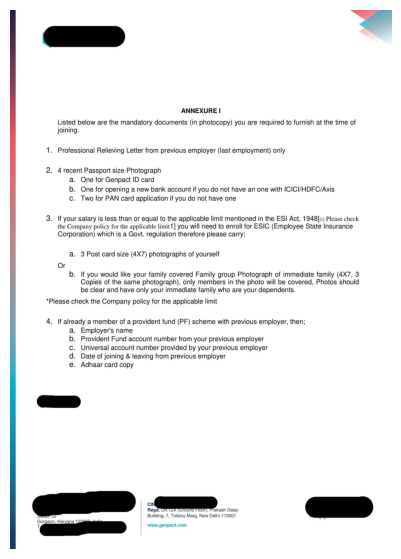

In [12]:
from PIL import Image
import matplotlib.pyplot as plt

image_path = os.path.join(images_dir, image_files[0])

img = Image.open(image_path).convert("RGB")

plt.figure(figsize=(7, 7))
plt.imshow(img)
plt.axis("off")
plt.show()

In [13]:
import os

annotations_dir = os.path.join(local_dir, "annotations")

print("Annotation files:")
print(os.listdir(annotations_dir)[:10])

Annotation files:
['kriyam_0064.json', 'kriyam_0430.json', 'kriyam_0648.json', 'kriyam_0180.json', 'kriyam_0795.json', 'kriyam_0083.json', 'kriyam_0111.json', 'kriyam_0977.json', 'kriyam_0566.json', 'kriyam_0478.json']


In [15]:
import os
import numpy as np
import pandas as pd

# Find metadata columns
print("Available columns:", df.columns.tolist())

filename_col = next(
    (c for c in ["filename", "image", "image_path", "file_name"]
     if c in df.columns), None
)

label_col = next(
    (c for c in ["is_authentic", "authentic"]
     if c in df.columns), None
)

id_col = next(
    (c for c in ["id", "document_id"]
     if c in df.columns), None
)

print("Filename column:", filename_col)
print("Label column:", label_col)
print("ID column:", id_col)

Available columns: ['file_name', 'id', 'tier', 'version', 'image_w', 'image_h', 'is_authentic', 'ai_generated_doc', 'num_regions', 'tamper_types']
Filename column: file_name
Label column: is_authentic
ID column: id


In [16]:
if not all([filename_col, label_col, id_col]):
    raise ValueError(
        "Required columns not identified. Share df.columns.tolist() output."
    )

df["image_path"] = df[filename_col].apply(
    lambda x: os.path.join(images_dir, os.path.basename(str(x)))
)

df["label"] = df[label_col].apply(
    lambda x: 0 if str(x).lower() in ["true", "1"] else 1
)

df = df[df["image_path"].apply(os.path.exists)].reset_index(drop=True)

print("Available images:", len(df))
print(df[["image_path", "label", id_col]].head())

Available images: 1752
                                          image_path  label           id
0  /root/.cache/huggingface/hub/datasets--kriyam-...      1  kriyam_0001
1  /root/.cache/huggingface/hub/datasets--kriyam-...      1  kriyam_0001
2  /root/.cache/huggingface/hub/datasets--kriyam-...      1  kriyam_0001
3  /root/.cache/huggingface/hub/datasets--kriyam-...      1  kriyam_0002
4  /root/.cache/huggingface/hub/datasets--kriyam-...      1  kriyam_0002


In [17]:
from PIL import Image
from tqdm.auto import tqdm

images = []
labels = []
document_ids = []

for _, row in tqdm(df.iterrows(), total=len(df)):

    try:
        img = Image.open(row["image_path"]).convert("RGB")
        img = img.resize((224, 224))

        images.append(np.array(img))
        labels.append(row["label"])
        document_ids.append(row[id_col])

    except Exception as e:
        print("Skipped:", row["image_path"], e)

X = np.array(images, dtype=np.uint8)
y = np.array(labels, dtype=np.int32)
groups = np.array(document_ids)

print("Images:", X.shape)
print("Labels:", y.shape)
print("Authentic:", np.sum(y == 0))
print("Tampered:", np.sum(y == 1))

  0%|          | 0/1752 [00:00<?, ?it/s]

Images: (1752, 224, 224, 3)
Labels: (1752,)
Authentic: 168
Tampered: 1584


In [32]:
from sklearn.model_selection import StratifiedGroupKFold

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

folds = list(sgkf.split(X, y, groups))

# Fold 0: Testing
test_idx = folds[0][1]

# Fold 1: Validation
val_idx = folds[1][1]

# Remaining folds: Training
train_idx = np.concatenate([
    folds[2][1],
    folds[3][1],
    folds[4][1]
])

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

print("Training:", len(train_idx))
print("Validation:", len(val_idx))
print("Testing:", len(test_idx))

print("\nTraining classes:")
print(pd.Series(y_train).value_counts())

print("\nValidation classes:")
print(pd.Series(y_val).value_counts())

print("\nTesting classes:")
print(pd.Series(y_test).value_counts())

Training: 1051
Validation: 346
Testing: 355

Training classes:
1    951
0    100
Name: count, dtype: int64

Validation classes:
1    314
0     32
Name: count, dtype: int64

Testing classes:
1    319
0     36
Name: count, dtype: int64


In [19]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [33]:
train_ids = set(groups[train_idx])
val_ids = set(groups[val_idx])
test_ids = set(groups[test_idx])

print("Train-Val overlap:", len(train_ids & val_ids))
print("Train-Test overlap:", len(train_ids & test_ids))
print("Val-Test overlap:", len(val_ids & test_ids))

Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0


In [34]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Class weights:", class_weights)

Class weights: {np.int32(0): np.float64(5.255), np.int32(1): np.float64(0.5525762355415352)}


In [35]:
X_train = X_train.astype("float32")
X_val = X_val.astype("float32")
X_test = X_test.astype("float32")

print("Minimum pixel:", X_train.min())
print("Maximum pixel:", X_train.max())

Minimum pixel: 0.0
Maximum pixel: 255.0


In [36]:
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Lambda(
        tf.keras.applications.mobilenet_v2.preprocess_input
    ),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(128, activation="relu"),

    layers.Dropout(0.2),

    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda_1 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [37]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),

    ModelCheckpoint(
        "best_document_forensics.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),

    epochs=15,
    batch_size=16,

    class_weight=class_weights,

    callbacks=callbacks
)

Epoch 1/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 23s 237ms/step - accuracy: 0.7003 - auc: 0.7177 - loss: 0.7762 - val_accuracy: 0.6994 - val_auc: 0.8401 - val_loss: 0.4849
Epoch 2/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.8421 - auc: 0.9330 - loss: 0.3492 - val_accuracy: 0.8324 - val_auc: 0.9239 - val_loss: 0.3273
Epoch 3/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.8906 - auc: 0.9705 - loss: 0.2336 - val_accuracy: 0.8988 - val_auc: 0.9524 - val_loss: 0.2429
Epoch 4/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.9267 - auc: 0.9851 - loss: 0.1706 - val_accuracy: 0.9133 - val_auc: 0.9627 - val_loss: 0.2055
Epoch 5/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.9448 - auc: 0.9918 - loss: 0.1272 - val_accuracy: 0.9364 - val_auc: 0.9610 - val_loss: 0.1561
Epoch 6/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.9581 - auc: 0.9940 - loss: 0.1058 - val_accuracy: 0.9364 - val_auc: 0.9790 - val_loss: 0.1148
Epoch 7/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 2s 24m

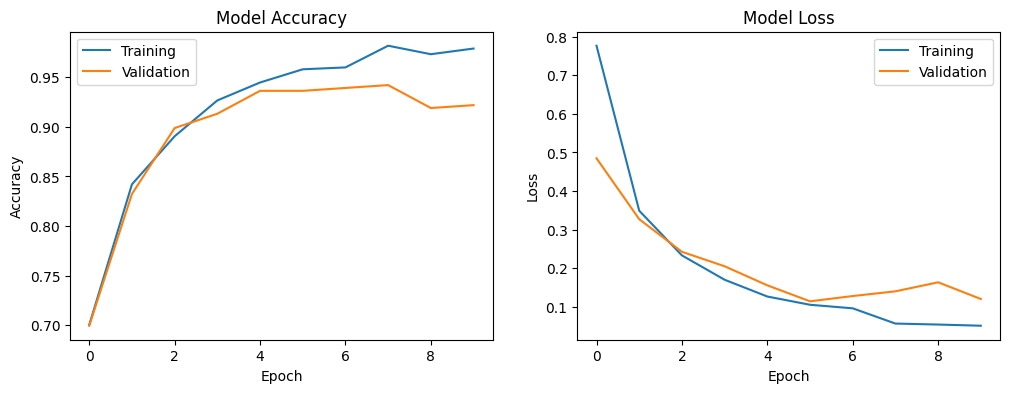

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

In [39]:
test_loss, test_accuracy, test_auc = model.evaluate(
    X_test,
    y_test
)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Test AUC:", round(test_auc, 4))

12/12 ━━━━━━━━━━━━━━━━━━━━ 6s 345ms/step - accuracy: 0.8986 - auc: 0.8698 - loss: 0.2516
Test Accuracy: 89.86 %
Test AUC: 0.8698


In [41]:
import numpy as np
from sklearn.metrics import (
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix
)

# Predict validation probabilities
val_prob = model.predict(X_val).ravel()

# Find the best threshold using validation data
thresholds = np.arange(0.10, 0.91, 0.02)

best_threshold = 0.5
best_score = 0

for threshold in thresholds:
    val_pred = (val_prob >= threshold).astype(int)

    score = balanced_accuracy_score(y_val, val_pred)

    if score > best_score:
        best_score = score
        best_threshold = threshold

print("Best threshold:", best_threshold)
print("Validation balanced accuracy:", best_score)

11/11 ━━━━━━━━━━━━━━━━━━━━ 4s 421ms/step
Best threshold: 0.9000000000000001
Validation balanced accuracy: 0.9570063694267517


In [42]:
test_prob = model.predict(X_test).ravel()

y_pred_new = (
    test_prob >= best_threshold
).astype(int)

print("Updated Classification Report:")

print(classification_report(
    y_test,
    y_pred_new,
    target_names=["Authentic", "Tampered"],
    zero_division=0
))

print("Updated Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_new))

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
Updated Classification Report:
              precision    recall  f1-score   support

   Authentic       0.44      0.64      0.52        36
    Tampered       0.96      0.91      0.93       319

    accuracy                           0.88       355
   macro avg       0.70      0.77      0.73       355
weighted avg       0.90      0.88      0.89       355

Updated Confusion Matrix:
[[ 23  13]
 [ 29 290]]


In [43]:
import json
import numpy as np

# Save trained model
model.save("/kaggle/working/document_forensics_model.keras")

# Save prediction configuration
config = {
    "threshold": float(best_threshold),
    "input_size": [224, 224],
    "labels": {
        "0": "Authentic",
        "1": "Tampered"
    },
    "model": "MobileNetV2"
}

with open(
    "/kaggle/working/model_config.json",
    "w"
) as f:
    json.dump(config, f, indent=4)

print("Model and configuration saved successfully!")

Model and configuration saved successfully!


In [44]:
from PIL import Image
import numpy as np

def predict_document(image_path):

    img = Image.open(image_path).convert("RGB")
    img = img.resize((224, 224))

    img_array = np.array(img, dtype=np.float32)
    img_array = np.expand_dims(img_array, axis=0)

    probability = model.predict(img_array, verbose=0)[0][0]

    if probability >= best_threshold:
        result = "Potentially Tampered"
        confidence = probability * 100
    else:
        result = "Potentially Authentic"
        confidence = (1 - probability) * 100

    print("Prediction:", result)
    print("Model confidence:", round(float(confidence), 2), "%")

    return result

In [45]:
test_image_path = os.path.join(
    images_dir,
    image_files[0]
)

predict_document(test_image_path)

Prediction: Potentially Tampered
Model confidence: 99.86 %


'Potentially Tampered'

In [46]:
!pip install -q ultralytics

In [4]:
import os
import json
import random
import shutil
import yaml
import numpy as np

from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split
from ultralytics import YOLO

random.seed(42)

images_dir = Path(local_dir) / "images"
annotations_dir = Path(local_dir) / "annotations"

output_dir = Path("/kaggle/working/yolo_dataset")

print("Images:", images_dir)
print("Annotations:", annotations_dir)
print("Image files:", len(list(images_dir.glob("*.png"))))
print("Annotation files:", len(list(annotations_dir.glob("*.json"))))

Images: /root/.cache/huggingface/hub/datasets--kriyam-ai--kriyam-tamperflow/snapshots/281155b75f62ea0db538dcff38d06109be58e912/images
Annotations: /root/.cache/huggingface/hub/datasets--kriyam-ai--kriyam-tamperflow/snapshots/281155b75f62ea0db538dcff38d06109be58e912/annotations
Image files: 2595
Annotation files: 1050


In [5]:
annotation_data = {}

for file in annotations_dir.glob("*.json"):

    with open(file, "r") as f:
        data = json.load(f)

    annotation_data[data["id"]] = data

print("Total documents:", len(annotation_data))

sample_id = list(annotation_data.keys())[0]

print(json.dumps(annotation_data[sample_id], indent=4))

Total documents: 1050
{
    "id": "kriyam_0064",
    "image_w": 2481,
    "image_h": 3508,
    "is_authentic": false,
    "ai_generated_doc": false,
    "regions": [
        {
            "region_id": 1,
            "x": 1210,
            "y": 174,
            "w": 478,
            "h": 325,
            "tamper_types": [
                "inpaint"
            ],
            "ai_modified": false
        }
    ],
    "notes": ""
}


In [6]:
doc_ids = list(annotation_data.keys())

doc_labels = [
    int(not annotation_data[doc_id]["is_authentic"])
    for doc_id in doc_ids
]

train_ids, temp_ids = train_test_split(
    doc_ids,
    test_size=0.30,
    random_state=42,
    stratify=doc_labels
)

temp_labels = [
    int(not annotation_data[doc_id]["is_authentic"])
    for doc_id in temp_ids
]

val_ids, test_ids = train_test_split(
    temp_ids,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

print("Training documents:", len(train_ids))
print("Validation documents:", len(val_ids))
print("Testing documents:", len(test_ids))

Training documents: 735
Validation documents: 157
Testing documents: 158


In [7]:
for split in ["train", "val", "test"]:

    (output_dir / "images" / split).mkdir(
        parents=True, exist_ok=True
    )

    (output_dir / "labels" / split).mkdir(
        parents=True, exist_ok=True
    )

print("YOLO folders created!")

YOLO folders created!


In [8]:
def convert_to_yolo(region, image_w, image_h):

    x = float(region["x"])
    y = float(region["y"])
    w = float(region["w"])
    h = float(region["h"])

    # Clip bounding box to image boundaries
    x1 = max(0, min(x, image_w))
    y1 = max(0, min(y, image_h))
    x2 = max(0, min(x + w, image_w))
    y2 = max(0, min(y + h, image_h))

    box_w = x2 - x1
    box_h = y2 - y1

    if box_w <= 0 or box_h <= 0:
        return None

    x_center = (x1 + x2) / (2 * image_w)
    y_center = (y1 + y2) / (2 * image_h)

    return (
        f"0 {x_center:.6f} {y_center:.6f} "
        f"{box_w/image_w:.6f} {box_h/image_h:.6f}"
    )

In [9]:
splits = {
    "train": train_ids,
    "val": val_ids,
    "test": test_ids
}

total_images = 0
missing_images = 0

for split, ids in splits.items():

    for doc_id in ids:

        annotation = annotation_data[doc_id]

        image_w = annotation["image_w"]
        image_h = annotation["image_h"]

        # Find C0, C2 and C4 versions
        for tier in ["C0", "C2", "C4"]:

            image_name = f"{doc_id}_{tier}.png"
            image_path = images_dir / image_name

            if not image_path.exists():
                missing_images += 1
                continue

            # Verify image dimensions
            with Image.open(image_path) as img:
                actual_w, actual_h = img.size

            if (actual_w, actual_h) != (image_w, image_h):
                print("Dimension mismatch:", image_name)
                continue

            # Copy image
            destination = (
                output_dir / "images" / split / image_name
            )

            shutil.copy2(image_path, destination)

            # Convert annotations
            label_path = (
                output_dir / "labels" / split /
                f"{Path(image_name).stem}.txt"
            )

            lines = []

            for region in annotation["regions"]:

                yolo_box = convert_to_yolo(
                    region, image_w, image_h
                )

                if yolo_box is not None:
                    lines.append(yolo_box)

            # Empty label file for authentic documents
            with open(label_path, "w") as f:
                f.write("\n".join(lines))

            total_images += 1

print("Prepared images:", total_images)
print("Missing images:", missing_images)

Prepared images: 2595
Missing images: 555


In [10]:
for split in ["train", "val", "test"]:

    image_count = len(
        list((output_dir / "images" / split).glob("*.png"))
    )

    label_count = len(
        list((output_dir / "labels" / split).glob("*.txt"))
    )

    print(
        split,
        "| Images:", image_count,
        "| Labels:", label_count
    )

train | Images: 1822 | Labels: 1822
val | Images: 383 | Labels: 383
test | Images: 390 | Labels: 390


In [11]:
data_config = {
    "path": str(output_dir),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {
        0: "tampered_region"
    }
}

yaml_path = output_dir / "data.yaml"

with open(yaml_path, "w") as f:
    yaml.dump(data_config, f, sort_keys=False)

print(yaml_path.read_text())

path: /kaggle/working/yolo_dataset
train: images/train
val: images/val
test: images/test
names:
  0: tampered_region



In [12]:
model2 = YOLO("yolov8n.pt")

results = model2.train(
    data=str(yaml_path),
    epochs=50,
    imgsz=640,
    batch=8,
    device=0,
    patience=10,
    workers=2,
    project="/kaggle/working/runs",
    name="document_tampering_detection"
)

Ultralytics 8.4.205 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=document_tampering_detection-2, nbs=64, nms=None, o

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/50      1.51G      1.725      1.587      1.226         47        640: 100% ━━━━━━━━━━━━ 228/228 2.6it/s 1:270.6sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 1.5it/s 16.1s0.3s
                   all        383       2587      0.487      0.421      0.392      0.183

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/50      1.51G      1.672      1.541      1.215         22        640: 100% ━━━━━━━━━━━━ 228/228 2.7it/s 1:250.6sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 24/24 1.4it/s 16.6s0.3s
                   all        383       2587      0.501      0.421      0.417      0.198

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/50      1.51G      1.672      1.508      1.215         30        640: 100% ━━━━━━━━━━━━ 228/228 2.7it/s 1:250.6sss
                 Class     I

In [14]:
best_model = YOLO(
    "/kaggle/working/runs/document_tampering_detection-2/weights/best.pt"
)

metrics = best_model.val(
    data=str(yaml_path),
    split="test",
    imgsz=640,
    device=0
)

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.205 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5183.5±980.2 MB/s, size: 1819.8 KB)
val: Scanning /kaggle/working/yolo_dataset/labels/test... 390 images, 154 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 390/390 532.7it/s 0.7s0.0s
val: New cache created: /kaggle/working/yolo_dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 1.3it/s 18.9s0.2s
                   all        390       1902      0.787      0.667       0.71      0.401
Speed: 0.7ms preprocess, 4.6ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to /kaggle/working/runs/detect/val
Precision: 0.787145866984053
Recall: 0.667192429022082
mAP50: 0.7096462755628856
mAP50-95: 0.4014389216621968


In [15]:
test_images = list(
    (output_dir / "images" / "test").glob("*.png")
)

test_image = str(test_images[0])

prediction = best_model.predict(
    source=test_image,
    conf=0.25,
    save=True
)

print("Test image:", test_image)
print("Prediction completed!")


image 1/1 /kaggle/working/yolo_dataset/images/test/kriyam_0218_C2.png: 352x640 9 tampered_regions, 8.9ms
Speed: 4.5ms preprocess, 8.9ms inference, 1.6ms postprocess per image at shape (1, 3, 352, 640)
Results saved to /kaggle/working/runs/detect/predict
Test image: /kaggle/working/yolo_dataset/images/test/kriyam_0218_C2.png
Prediction completed!


In [17]:
from pathlib import Path

best_model_path = Path(
    "/kaggle/working/runs/document_tampering_detection-2/weights/best.pt"
)

if best_model_path.exists():
    print("YOLOv8 training completed!")
    print("Best model:", best_model_path)
else:
    print("Training is not completed or best.pt was not saved.")

YOLOv8 training completed!
Best model: /kaggle/working/runs/document_tampering_detection-2/weights/best.pt


In [18]:
from ultralytics import YOLO

best_model = YOLO(str(best_model_path))

metrics = best_model.val(
    data=str(yaml_path),
    split="test",
    imgsz=640
)

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.205 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 73 layers, 3,132,707 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 5305.4±1154.4 MB/s, size: 2229.9 KB)
val: Scanning /kaggle/working/yolo_dataset/labels/test.cache... 390 images, 154 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 390/390 125.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 1.3it/s 18.7s0.2s
                   all        390       1902      0.787      0.667       0.71      0.401
Speed: 0.7ms preprocess, 4.2ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to /kaggle/working/runs/detect/val-2
Precision: 0.787145866984053
Recall: 0.667192429022082
mAP50: 0.7096462755628856
mAP50-95: 0.4014389216621968


In [19]:
!pip install -q paddleocr paddlepaddle

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
kaggle-environments 1.33.3 requires PyYAML>=6.0.3, but you have pyyaml 6.0.2 which is incompatible.
ydata-profiling 4.18.4 requires PyYAML<6.1,>=6.0.3, but you have pyyaml 6.0.2 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [22]:
import easyocr
import torch

reader = easyocr.Reader(
    ['en'],
    gpu=torch.cuda.is_available()
)

print("EasyOCR model loaded successfully!")

EasyOCR model loaded successfully!


In [23]:
from pathlib import Path

image_path = next(images_dir.glob("*.png"))

print("Testing:", image_path.name)

results = reader.readtext(
    str(image_path),
    detail=0,
    paragraph=True
)

for text in results:
    print(text)

Testing: kriyam_0542_C2.png
ANNEXURE
Listed below are the mandatory documents (in photocopy) you are required to furnish at the time of joining:
1
Professional Relieving Letter from previous employer (last employment) only
2 4 recent Passport size Photograph a One for Genpact ID card b One for opening a new bank account if you do not have an one with ICICIIHDFCIAxis C. Two for PAN card application if you do not have one
3 If your salary is less than or equal to the applicable limit mentioned in the ESI Act; 1948[u1 Please check the Company policy for the applicable limit1] you will need to enroll for ESIC (Employee State Insurance Corporation) which is a Govt: regulation therefore please carry;
a_ 3 Post card size (4X7) photographs of yourself Or b If you would like your family covered Family group Photograph of immediate family (4X7 , 3 Copies of the same photograph) , only members in the photo will be covered, Photos should be clear and have only your immediate family who are your de

In [24]:
import json

ocr_output_dir = Path("/kaggle/working/ocr_results")
ocr_output_dir.mkdir(parents=True, exist_ok=True)

image_files = sorted(images_dir.glob("*.png"))[:50]

extracted_documents = []

for i, image_path in enumerate(image_files):

    try:
        results = reader.readtext(
            str(image_path),
            detail=0,
            paragraph=True
        )

        document_text = "\n".join(results)

        extracted_documents.append({
            "document_name": image_path.name,
            "extracted_text": document_text
        })

        print(f"Processed {i+1}/{len(image_files)}")

    except Exception as e:
        print("Error:", image_path.name, e)

print("OCR extraction completed!")
print("Total extracted:", len(extracted_documents))

Processed 1/50
Processed 2/50
Processed 3/50
Processed 4/50
Processed 5/50
Processed 6/50
Processed 7/50
Processed 8/50
Processed 9/50
Processed 10/50
Processed 11/50
Processed 12/50
Processed 13/50
Processed 14/50
Processed 15/50
Processed 16/50
Processed 17/50
Processed 18/50
Processed 19/50
Processed 20/50
Processed 21/50
Processed 22/50
Processed 23/50
Processed 24/50
Processed 25/50
Processed 26/50
Processed 27/50
Processed 28/50
Processed 29/50
Processed 30/50
Processed 31/50
Processed 32/50
Processed 33/50
Processed 34/50
Processed 35/50
Processed 36/50
Processed 37/50
Processed 38/50
Processed 39/50
Processed 40/50
Processed 41/50
Processed 42/50
Processed 43/50
Processed 44/50
Processed 45/50
Processed 46/50
Processed 47/50
Processed 48/50
Processed 49/50
Processed 50/50
OCR extraction completed!
Total extracted: 50


In [25]:
output_file = ocr_output_dir / "extracted_documents.json"

with open(output_file, "w", encoding="utf-8") as f:
    json.dump(
        extracted_documents,
        f,
        indent=4,
        ensure_ascii=False
    )

print("Saved successfully:", output_file)

Saved successfully: /kaggle/working/ocr_results/extracted_documents.json


In [26]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

model_name = "Qwen/Qwen2.5-1.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(model_name)

llm_model = AutoModelForCausalLM.from_pretrained(
    model_name,
    torch_dtype="auto",
    device_map="auto"
)

print("Qwen2.5 loaded successfully!")

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen2.5 loaded successfully!


In [32]:
def analyze_document_fast(document_text):

    prompt = f"""
Analyze this document for potential inconsistencies.

Identify:
1. Important names, dates and amounts.
2. Unusual or conflicting information.
3. Missing information.
4. Evidence requiring human investigation.

Do not assume fraud. Do not invent facts.

Document:
{document_text}

Give a short structured analysis.
"""

    messages = [
        {"role": "user", "content": prompt}
    ]

    formatted_prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        formatted_prompt,
        return_tensors="pt",
        truncation=True,
        max_length=1024
    ).to(llm_model.device)

    with torch.inference_mode():
        outputs = llm_model.generate(
            **inputs,
            max_new_tokens=150,
            do_sample=False,
            use_cache=True
        )

    return tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

In [33]:
# Select only 3 documents for testing

test_documents = extracted_documents[:3]

for doc in test_documents:
    doc["extracted_text"] = doc["extracted_text"][:1500]

print("Documents selected:", len(test_documents))

Documents selected: 3


In [35]:
result = analyze_document_fast(
    test_documents[0]["extracted_text"]
)

print(result)

### Analysis of the Document:

#### 1. **Important Names, Dates, and Amounts**

**Names:**  
- Mr.:  
- Patient Name: N/A (Missing)

**Dates:**  
- Date of Collection: 21/Jan/2026 12:20 AM  
- Date of Reception: 21/Jan/2026 06:51 AM  
- Date of Reporting: 21/Jan/2026 07:27 AM  

**Amounts:**  
- Volume of Sample: 1950 mL  
- pH Value: 7.054  
- Sodium Concentration: 135 mmol/L


In [36]:
fast_results = []

for doc in test_documents:

    result = analyze_document_fast(
        doc["extracted_text"]
    )

    fast_results.append({
        "document_name": doc["document_name"],
        "analysis": result
    })

print("Completed:", len(fast_results))

Completed: 3


In [38]:
import json
from pathlib import Path

output_dir = Path("/kaggle/working/outputs")
output_dir.mkdir(exist_ok=True)

context_file = output_dir / "contextual_analysis_fast.json"

with open(context_file, "w", encoding="utf-8") as f:
    json.dump(
        fast_results,
        f,
        indent=4,
        ensure_ascii=False
    )

print("Contextual results saved!")
print("File:", context_file)
print("Total analyzed:", len(fast_results))

Contextual results saved!
File: /kaggle/working/outputs/contextual_analysis_fast.json
Total analyzed: 3


In [39]:
for item in fast_results:
    print("\nDocument:", item["document_name"])
    print("-" * 50)
    print(item["analysis"])


Document: kriyam_0001_C0.png
--------------------------------------------------
### Analysis of the Document:

#### 1. **Important Names, Dates, and Amounts**

**Names:**  
- Mr.:  
- Patient Name: N/A (Missing)

**Dates:**  
- Date of Collection: 21/Jan/2026 12:20 AM  
- Date of Reception: 21/Jan/2026 06:51 AM  
- Date of Reporting: 21/Jan/2026 07:27 AM  

**Amounts:**  
- Volume of Sample: 1950 mL  
- pH Value: 7.054  
- Sodium Concentration: 135 mmol/L

Document: kriyam_0001_C2.png
--------------------------------------------------
### Analysis of the Document:

#### 1. **Important Names, Dates, and Amounts**

**Names:**
- **Patient Name:** Mr.
- **Client Code:** 85
- **Visit ID:** QSD25793
- **Health ID:** 131897
- **ICU:** Yes (as indicated in the report)

**Dates:**
- **Date of Collection:** 21/Jan/2026 12:20AM
- **Date of Receipt:** 21/Jan/2026 06:51AM
- **Date of Reporting:** 21/Jan/2026 07

Document: kriyam_0001_C4.png
--------------------------------------------------
### An

In [41]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

print("Sentence-BERT loaded successfully!")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Sentence-BERT loaded successfully!


In [42]:
documents = [
    doc for doc in extracted_documents
    if doc.get("extracted_text", "").strip()
]

document_texts = [
    doc["extracted_text"] for doc in documents
]

embeddings = embedding_model.encode(
    document_texts,
    convert_to_numpy=True,
    show_progress_bar=True
)

print("Embeddings generated:", embeddings.shape)

Batches:   0%|          | 0/2 [00:00<?, ?it/s]

Embeddings generated: (50, 384)


In [43]:
import numpy as np
import re

similarity_matrix = cosine_similarity(embeddings)

def get_source_id(filename):
    # Remove compression tier, e.g. C0, C2 or C4
    return re.sub(r"_C[024]\.png$", "", filename)

comparison_results = []

for i in range(len(documents)):
    for j in range(i + 1, len(documents)):

        # Do not compare compression versions of the same source
        id1 = get_source_id(documents[i]["document_name"])
        id2 = get_source_id(documents[j]["document_name"])

        if id1 == id2:
            continue

        score = float(similarity_matrix[i][j])

        comparison_results.append({
            "document_1": documents[i]["document_name"],
            "document_2": documents[j]["document_name"],
            "similarity_score": round(score, 4)
        })

comparison_results.sort(
    key=lambda x: x["similarity_score"],
    reverse=True
)

print("Document comparisons completed!")
print("Total comparisons:", len(comparison_results))

Document comparisons completed!
Total comparisons: 1176


In [44]:
import pandas as pd

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.head(10))

,document_1,document_2,similarity_score
0,kriyam_0009_C4.png,kriyam_0016_C4.png,0.7857
1,kriyam_0009_C2.png,kriyam_0016_C4.png,0.7654
2,kriyam_0009_C4.png,kriyam_0016_C0.png,0.7569
3,kriyam_0009_C4.png,kriyam_0016_C2.png,0.7492
4,kriyam_0009_C0.png,kriyam_0016_C0.png,0.7288
5,kriyam_0008_C0.png,kriyam_0009_C0.png,0.7251
6,kriyam_0009_C2.png,kriyam_0016_C0.png,0.7247
7,kriyam_0009_C2.png,kriyam_0016_C2.png,0.7235
8,kriyam_0008_C2.png,kriyam_0009_C0.png,0.7216
9,kriyam_0009_C0.png,kriyam_0016_C2.png,0.7211


In [45]:
def compare_documents(text1, text2):

    prompt = f"""
You are a document forensic comparison assistant.

Compare the following two documents.

DOCUMENT 1:
{text1}

DOCUMENT 2:
{text2}

Identify:
1. Matching information.
2. Conflicting names, dates, amounts or identification details.
3. Missing information.
4. Potential inconsistencies requiring investigation.

Return:
- Finding
- Evidence from Document 1
- Evidence from Document 2
- Explanation
- Recommended verification

Important:
Do not assume that differences prove fraud.
Do not invent information.
"""

    messages = [{"role": "user", "content": prompt}]

    formatted_prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        formatted_prompt,
        return_tensors="pt"
    ).to(llm_model.device)

    with torch.no_grad():
        outputs = llm_model.generate(
            **inputs,
            max_new_tokens=400,
            do_sample=False
        )

    return tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

In [46]:
if len(comparison_results) > 0:

    pair = comparison_results[0]

    doc1 = next(
        d for d in documents
        if d["document_name"] == pair["document_1"]
    )

    doc2 = next(
        d for d in documents
        if d["document_name"] == pair["document_2"]
    )

    print("Document 1:", pair["document_1"])
    print("Document 2:", pair["document_2"])
    print("Similarity:", pair["similarity_score"])

    result = compare_documents(
        doc1["extracted_text"],
        doc2["extracted_text"]
    )

    print("\nCROSS-DOCUMENT INVESTIGATION")
    print("=" * 60)
    print(result)

else:
    print("No eligible document pairs found.")

Document 1: kriyam_0009_C4.png
Document 2: kriyam_0016_C4.png
Similarity: 0.7857

CROSS-DOCUMENT INVESTIGATION
### Finding:

**Matching Information:**
- **Patient Name:** Both documents list "Patient Name" as "2602210030".
- **Age and Set:** Both documents indicate "Age / Set" as "72 Yrs; 6 Months 12 Days Male".

**Conflicting Names, Dates, Amounts, or Identification Details:**
- **Document 1:**
  - **Consultant Phone Numbers:** The phone numbers listed in Document 1 do not match those provided in Document 2.
  - **Collection Time Reportine Data:** The time recorded is different (20 pm vs. 20 pm).
  
- **Document 2:**
  - **Consultant Phone Numbers:** The phone numbers listed in Document 2 do not match those provided in Document 1.
  - **Collection Time Reportine Data:** The time recorded is different (20 pm vs. 20 pm).

**Missing Information:**
- **Document 1:**
  - **Electrolytes:** There is no mention of electrolytes in Document 1.
  
- **Document 2:**
  - **Electrolytes:** There is

In [47]:
import json

output_path = "/kaggle/working/cross_document_results.json"

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(
        comparison_results,
        f,
        indent=4,
        ensure_ascii=False
    )

print("Cross-document results saved:", output_path)

Cross-document results saved: /kaggle/working/cross_document_results.json


In [48]:
!pip install -q langgraph langchain langchain-core

In [49]:
from typing import TypedDict, List, Dict, Any
from langgraph.graph import StateGraph, START, END

print("LangGraph imported successfully!")

LangGraph imported successfully!


In [50]:
class InvestigationState(TypedDict, total=False):

    document_paths: List[str]

    extracted_documents: List[Dict[str, Any]]

    visual_findings: List[Dict[str, Any]]

    contextual_findings: List[Dict[str, Any]]

    comparison_findings: List[Dict[str, Any]]

    evidence: List[Dict[str, Any]]

    investigation_report: str

    investigation_status: str

In [51]:
def ocr_agent(state: InvestigationState):
    print("Agent 1: OCR & Document Extraction")

    return {
        "extracted_documents": state.get("extracted_documents", [])
    }


def visual_agent(state: InvestigationState):
    print("Agent 2: Visual Forensic Analysis")

    return {
        "visual_findings": []
    }


def contextual_agent(state: InvestigationState):
    print("Agent 3: Contextual Analysis")

    return {
        "contextual_findings": []
    }


def comparison_agent(state: InvestigationState):
    print("Agent 4: Cross-Document Comparison")

    return {
        "comparison_findings": []
    }


def evidence_agent(state: InvestigationState):
    print("Agent 5: Evidence Investigation")

    return {
        "evidence": []
    }


def report_agent(state: InvestigationState):
    print("Agent 6: Investigation Report")

    return {
        "investigation_report": "Investigation report generation pending.",
        "investigation_status": "Completed"
    }

In [52]:
workflow = StateGraph(InvestigationState)

workflow.add_node("ocr", ocr_agent)
workflow.add_node("visual", visual_agent)
workflow.add_node("contextual", contextual_agent)
workflow.add_node("comparison", comparison_agent)
workflow.add_node("evidence", evidence_agent)
workflow.add_node("report", report_agent)

workflow.add_edge(START, "ocr")
workflow.add_edge("ocr", "visual")
workflow.add_edge("visual", "contextual")
workflow.add_edge("contextual", "comparison")
workflow.add_edge("comparison", "evidence")
workflow.add_edge("evidence", "report")
workflow.add_edge("report", END)

app = workflow.compile()

print("LangGraph workflow created successfully!")

LangGraph workflow created successfully!


In [53]:
initial_state = {
    "document_paths": [],
    "extracted_documents": extracted_documents[:3],
    "investigation_status": "Started"
}

final_result = app.invoke(initial_state)

print("\nWorkflow Status:", final_result["investigation_status"])
print("Investigation Report:", final_result["investigation_report"])

Agent 1: OCR & Document Extraction
Agent 2: Visual Forensic Analysis
Agent 3: Contextual Analysis
Agent 4: Cross-Document Comparison
Agent 5: Evidence Investigation
Agent 6: Investigation Report

Workflow Status: Completed
Investigation Report: Investigation report generation pending.


In [54]:
import tensorflow as tf
import numpy as np
from PIL import Image
from pathlib import Path

def visual_forensic_agent(image_path):

    image = Image.open(image_path).convert("RGB")

    # MobileNetV2 classification
    resized = image.resize((224, 224))
    image_array = np.array(resized, dtype=np.float32)

    input_array = np.expand_dims(image_array, axis=0)

    classification_score = float(
        model.predict(input_array, verbose=0)[0][0]
    )

    threshold = float(best_threshold)

    classification = (
        "Potentially Tampered"
        if classification_score >= threshold
        else "Likely Authentic"
    )

    # YOLOv8 region detection
    detections = best_model.predict(
        source=str(image_path),
        conf=0.25,
        verbose=False
    )

    regions = []

    for detection in detections:
        for box in detection.boxes:
            regions.append({
                "coordinates": box.xyxy[0].cpu().tolist(),
                "confidence": float(box.conf[0].cpu()),
                "class": int(box.cls[0].cpu())
            })

    return {
        "document": Path(image_path).name,
        "classification": classification,
        "tampering_score": classification_score,
        "detected_regions": regions
    }

print("Visual Forensic Agent connected!")

I0000 00:00:1794080436.169251   18583 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Visual Forensic Agent connected!


In [55]:
def document_extraction_agent(image_path):

    results = reader.readtext(
        str(image_path),
        detail=1
    )

    extracted_items = []

    for item in results:

        coordinates, text_value, confidence = item

        extracted_items.append({
            "text": text_value,
            "confidence": float(confidence),
            "coordinates": coordinates
        })

    return {
        "document": Path(image_path).name,
        "extracted_fields": extracted_items,
        "full_text": " ".join(
            item["text"] for item in extracted_items
        )
    }

print("OCR Extraction Agent connected!")

OCR Extraction Agent connected!


In [59]:
from ultralytics import YOLO

yolo_path = "/kaggle/working/runs/document_tampering_detection-2/weights/best.pt"

best_model = YOLO(yolo_path)

print("YOLOv8 model loaded successfully!")

YOLOv8 model loaded successfully!


In [61]:
import tensorflow as tf

from tensorflow.keras.models import load_model
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

model_path = "/kaggle/working/document_forensics_model.keras"

model = load_model(
    model_path,
    custom_objects={
        "preprocess_input": preprocess_input
    },
    compile=False
)

print("MobileNetV2 loaded successfully!")

MobileNetV2 loaded successfully!


In [62]:
print("MobileNetV2:", model is not None)
print("YOLOv8:", best_model is not None)

print("MobileNetV2 input:", model.input_shape)

MobileNetV2: True
YOLOv8: True
MobileNetV2 input: (None, 224, 224, 3)


In [73]:
import json

config_path = "/kaggle/working/model_config.json"

with open(config_path, "r") as f:
    config = json.load(f)

best_threshold = float(config["threshold"])

print("Best threshold:", best_threshold)
print("Model:", config["model"])
print("Input size:", config["input_size"])

Best threshold: 0.9000000000000001
Model: MobileNetV2
Input size: [224, 224]


In [75]:
import numpy as np
from PIL import Image
from pathlib import Path

def visual_forensic_agent(image_path):

    image_path = Path(image_path)

    # 1. Load image
    image = Image.open(image_path).convert("RGB")

    # 2. MobileNetV2 classification
    resized = image.resize((224, 224))

    image_array = np.array(resized, dtype=np.float32)
    input_array = np.expand_dims(image_array, axis=0)

    classification_score = float(
        model.predict(input_array, verbose=0)[0][0]
    )

    classification = (
        "Potentially Tampered"
        if classification_score >= best_threshold
        else "Likely Authentic"
    )

    # 3. YOLOv8 region detection
    detections = best_model.predict(
        source=str(image_path),
        conf=0.25,
        verbose=False
    )

    regions = []

    for detection in detections:
        for box in detection.boxes:

            regions.append({
                "coordinates": box.xyxy[0].cpu().tolist(),
                "confidence": float(box.conf[0].cpu()),
                "class": int(box.cls[0].cpu())
            })

    # 4. Return findings
    return {
        "document": image_path.name,
        "classification": classification,
        "tampering_score": round(classification_score, 4),
        "threshold": best_threshold,
        "detected_regions": regions,
        "number_of_suspicious_regions": len(regions)
    }

print("Visual Forensic Agent created successfully!")

Visual Forensic Agent created successfully!


In [76]:
from pathlib import Path

images_dir = Path("/kaggle/working/yolo_dataset/images/test")

test_image = next(
    p for p in images_dir.iterdir()
    if p.suffix.lower() in [".png", ".jpg", ".jpeg"]
)

visual_result = visual_forensic_agent(test_image)

import json
print(json.dumps(visual_result, indent=4))

{
    "document": "kriyam_0218_C2.png",
    "classification": "Potentially Tampered",
    "tampering_score": 0.9947,
    "threshold": 0.9000000000000001,
    "detected_regions": [
        {
            "coordinates": [
                730.0272827148438,
                341.33819580078125,
                999.7020263671875,
                493.56207275390625
            ],
            "confidence": 0.7994643449783325,
            "class": 0
        },
        {
            "coordinates": [
                12.753504753112793,
                181.865234375,
                290.5460205078125,
                216.01937866210938
            ],
            "confidence": 0.7416980862617493,
            "class": 0
        },
        {
            "coordinates": [
                208.5836181640625,
                152.30857849121094,
                467.35711669921875,
                185.370849609375
            ],
            "confidence": 0.7016831636428833,
            "class": 0
        },


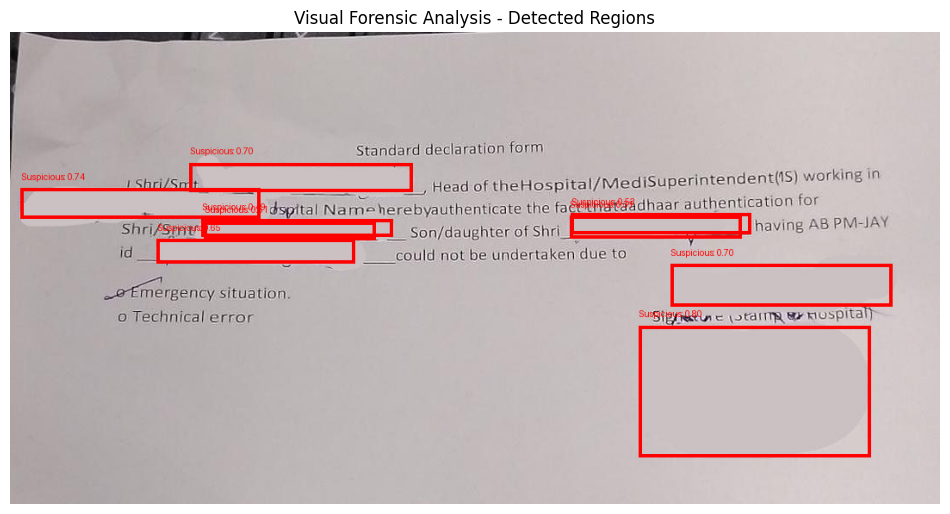

Annotated image saved: /kaggle/working/visual_forensic_result.png


In [77]:
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

# Load original document
image = Image.open(test_image).convert("RGB")
draw = ImageDraw.Draw(image)

# Draw YOLOv8 bounding boxes
for region in visual_result["detected_regions"]:

    x1, y1, x2, y2 = region["coordinates"]
    confidence = region["confidence"]

    draw.rectangle(
        [x1, y1, x2, y2],
        outline="red",
        width=4
    )

    draw.text(
        (x1, max(0, y1 - 20)),
        f"Suspicious: {confidence:.2f}",
        fill="red"
    )

# Display annotated document
plt.figure(figsize=(12, 12))
plt.imshow(image)
plt.axis("off")
plt.title("Visual Forensic Analysis - Detected Regions")
plt.show()

# Save annotated image
output_path = "/kaggle/working/visual_forensic_result.png"
image.save(output_path)

print("Annotated image saved:", output_path)

In [78]:
import easyocr
import torch
from pathlib import Path

# Initialize EasyOCR
reader = easyocr.Reader(
    ['en'],
    gpu=torch.cuda.is_available()
)

def document_extraction_agent(image_path):

    image_path = Path(image_path)

    # Extract text with coordinates and confidence
    results = reader.readtext(
        str(image_path),
        detail=1
    )

    extracted_items = []

    for coordinates, text_value, confidence in results:

        extracted_items.append({
            "text": text_value,
            "confidence": float(confidence),
            "coordinates": coordinates
        })

    full_text = " ".join(
        item["text"] for item in extracted_items
    )

    return {
        "document": image_path.name,
        "extracted_fields": extracted_items,
        "full_text": full_text,
        "total_text_regions": len(extracted_items)
    }

print("OCR Agent created successfully!")

OCR Agent created successfully!


In [79]:
ocr_result = document_extraction_agent(test_image)

print("Document:", ocr_result["document"])
print("Total text regions:", ocr_result["total_text_regions"])

print("\nExtracted Text:\n")
print(ocr_result["full_text"])

Document: kriyam_0218_C2.png
Total text regions: 12

Extracted Text:

Standard declaration form Shri/Smt Head of theHospitalMediSuperintendents) working in dspital Nameherebyauthenticate the fact thataadhaar authentication for ShrifSmt Son/daughter of Shri having A8 PM-JAY could not be undertaken due to ~@Emergency situation: Technical error Sigrtui € (3tai @ nuspital)


In [81]:
print("tokenizer:", "Available" if "tokenizer" in globals() else "Missing")
print("llm_model:", "Available" if "llm_model" in globals() else "Missing")

tokenizer: Available
llm_model: Available


In [82]:
def contextual_analysis_agent(ocr_result):

    document_text = ocr_result["full_text"]

    prompt = f"""
You are a document forensic investigation assistant.

Analyze the following extracted document text.

Identify:
1. Important names, dates and amounts.
2. Unusual or inconsistent information.
3. Missing information.
4. Details that require human investigation.

Do not assume fraud.
Do not invent information.
Only use the supplied document text.

DOCUMENT TEXT:
{document_text[:2000]}

Provide a short structured analysis.
"""

    messages = [
        {"role": "user", "content": prompt}
    ]

    formatted_prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        formatted_prompt,
        return_tensors="pt",
        truncation=True,
        max_length=1024
    ).to(llm_model.device)

    with torch.inference_mode():

        outputs = llm_model.generate(
            **inputs,
            max_new_tokens=150,
            do_sample=False,
            use_cache=True
        )

    response = tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

    return {
        "document": ocr_result["document"],
        "contextual_analysis": response
    }

print("Contextual Analysis Agent created successfully!")

Contextual Analysis Agent created successfully!


In [83]:
context_result = contextual_analysis_agent(ocr_result)

print("Document:", context_result["document"])
print("\nContextual Analysis:\n")
print(context_result["contextual_analysis"])

Document: kriyam_0218_C2.png

Contextual Analysis:

### Structured Analysis:

#### 1. **Important Names, Dates and Amounts**
- **Name:** Shri/Smt Head of the Hospital
- **Date:** Not explicitly mentioned but implied as part of the standard declaration form.
- **Amount:** Not applicable as it is a declaration form rather than an accounting document.

#### 2. **Unusual or Inconsistent Information**
- **"Aadhaar Authentication":** This term is used inconsistently throughout the text. It appears once as "aadhaar authentication" and twice as "aadhaar authentication." The first instance seems to be a typo or misspelling, while the second might be intended to convey the same concept.
  
- **"Technical Error":** This phrase


In [84]:
def cross_document_comparison_agent(documents):

    valid_documents = [
        doc for doc in documents
        if doc.get("full_text", "").strip()
    ]

    if len(valid_documents) < 2:
        return {
            "message": "At least two documents are required."
        }

    texts = [doc["full_text"] for doc in valid_documents]

    # Generate document embeddings
    embeddings = embedding_model.encode(
        texts,
        convert_to_numpy=True,
        show_progress_bar=False
    )

    # Calculate similarity
    similarity_matrix = cosine_similarity(embeddings)

    comparisons = []

    for i in range(len(valid_documents)):
        for j in range(i + 1, len(valid_documents)):

            comparisons.append({
                "document_1": valid_documents[i]["document"],
                "document_2": valid_documents[j]["document"],
                "similarity_score": round(
                    float(similarity_matrix[i][j]), 4
                )
            })

    comparisons.sort(
        key=lambda x: x["similarity_score"],
        reverse=True
    )

    return {
        "total_documents": len(valid_documents),
        "total_comparisons": len(comparisons),
        "comparisons": comparisons
    }

print("Cross-Document Comparison Agent created successfully!")

Cross-Document Comparison Agent created successfully!


In [85]:
import json

ocr_file = "/kaggle/working/ocr_results/extracted_documents.json"

with open(ocr_file, "r") as f:
    saved_documents = json.load(f)

print("Available OCR documents:", len(saved_documents))
print("Sample:", saved_documents[0].keys())

Available OCR documents: 50
Sample: dict_keys(['document_name', 'extracted_text'])


In [86]:
comparison_result = cross_document_comparison_agent(
    saved_documents[:10]
)

print(json.dumps(comparison_result, indent=4))

{
    "message": "At least two documents are required."
}


In [87]:
import json

ocr_file = "/kaggle/working/ocr_results/extracted_documents.json"

with open(ocr_file, "r") as f:
    saved_documents = json.load(f)

print("Total documents:", len(saved_documents))

for doc in saved_documents[:3]:
    print("\nDocument keys:", doc.keys())
    print("Document name:", doc.get("document_name"))
    print("Extracted text:", doc.get("extracted_text", "")[:300])

Total documents: 50

Document keys: dict_keys(['document_name', 'extracted_text'])
Document name: kriyam_0001_C0.png
Extracted text: RADIOMETER ABLSOO BASIC ABLOQO BASIC PATIENT REPORT 05,.33 AM Syringe 5 1950L Sampiz # Identifications Pallent ID 12026522 Patient First Namie Sample tyre No: specified 37.0 -C
213/2026 3971
Blnod Gas Values PH
7 054
Pure Health D: 13182Z JCLL PatientName Mr:. Age/Gender 87 Y 2 DIM Barcode No 9sd080

Document keys: dict_keys(['document_name', 'extracted_text'])
Document name: kriyam_0001_C2.png
Extracted text: RADIOMETER ABLSOO BASIC ABLOQO BASIC PATIENT REPORT 05,.33 AM Syringe 8 1950L Sampiz # Identifications Pallent ID 12025522 Patient First Namie Sample tyre No: specified 37,.0 -C
213/2026 3971
Blnod Gas Values PH
7 054
Pure Health J:131897 JCU PatientName Mr. Age/Gender 87 Y 2 DM Barcode No 9sd080049

Document keys: dict_keys(['document_name', 'extracted_text'])
Document name: kriyam_0001_C4.png
Extracted text: RADIOMETER ABLSOO BASIC ABLJOO BASIC PA

In [88]:
comparison_documents = []

for doc in saved_documents:
    text_value = doc.get("full_text") or doc.get("extracted_text", "")

    if text_value.strip():
        comparison_documents.append({
            "document": doc.get("document") or doc.get("document_name"),
            "full_text": text_value
        })

print("Valid documents:", len(comparison_documents))

Valid documents: 50


In [89]:
comparison_result = cross_document_comparison_agent(
    comparison_documents[:10]
)

print(json.dumps(comparison_result, indent=4))

{
    "total_documents": 10,
    "total_comparisons": 45,
    "comparisons": [
        {
            "document_1": "kriyam_0002_C0.png",
            "document_2": "kriyam_0002_C2.png",
            "similarity_score": 0.9702
        },
        {
            "document_1": "kriyam_0001_C0.png",
            "document_2": "kriyam_0001_C4.png",
            "similarity_score": 0.9588
        },
        {
            "document_1": "kriyam_0003_C2.png",
            "document_2": "kriyam_0003_C4.png",
            "similarity_score": 0.9581
        },
        {
            "document_1": "kriyam_0001_C0.png",
            "document_2": "kriyam_0001_C2.png",
            "similarity_score": 0.9573
        },
        {
            "document_1": "kriyam_0001_C2.png",
            "document_2": "kriyam_0001_C4.png",
            "similarity_score": 0.9483
        },
        {
            "document_1": "kriyam_0002_C0.png",
            "document_2": "kriyam_0002_C4.png",
            "similarity_score": 0.9

In [90]:
import json
from pathlib import Path

def evidence_investigation_agent(
    visual_result,
    ocr_result,
    context_result=None,
    comparison_result=None
):

    evidence_items = []

    # Get suspicious regions from YOLO
    suspicious_regions = visual_result.get(
        "detected_regions", []
    )

    # Get extracted OCR text
    extracted_fields = ocr_result.get(
        "extracted_fields", []
    )

    # Match OCR text with suspicious regions
    for index, region in enumerate(suspicious_regions):

        x1, y1, x2, y2 = region["coordinates"]

        matched_text = []

        for field in extracted_fields:

            coordinates = field["coordinates"]

            # Calculate center of OCR text region
            center_x = sum(point[0] for point in coordinates) / len(coordinates)
            center_y = sum(point[1] for point in coordinates) / len(coordinates)

            # Check whether OCR text is inside YOLO box
            if x1 <= center_x <= x2 and y1 <= center_y <= y2:

                matched_text.append({
                    "text": field["text"],
                    "ocr_confidence": field["confidence"]
                })

        evidence_items.append({
            "evidence_id": f"EVIDENCE_{index + 1}",
            "document": visual_result["document"],
            "page": 1,
            "evidence_type": "Potentially suspicious visual region",
            "bounding_box": region["coordinates"],
            "detection_confidence": region["confidence"],
            "related_text": matched_text
        })

    # Add overall classification evidence
    evidence_items.append({
        "evidence_id": f"EVIDENCE_{len(evidence_items) + 1}",
        "document": visual_result["document"],
        "evidence_type": "Document-level classification",
        "classification": visual_result["classification"],
        "tampering_score": visual_result["tampering_score"],
        "threshold": visual_result["threshold"]
    })

    return {
        "document": visual_result["document"],
        "total_evidence_items": len(evidence_items),
        "evidence": evidence_items,
        "contextual_analysis": (
            context_result.get("contextual_analysis")
            if context_result else None
        ),
        "cross_document_comparison": comparison_result
    }


print("Evidence Investigation Agent created successfully!")

Evidence Investigation Agent created successfully!


In [91]:
evidence_result = evidence_investigation_agent(
    visual_result=visual_result,
    ocr_result=ocr_result,
    context_result=context_result if "context_result" in globals() else None,
    comparison_result=comparison_result if "comparison_result" in globals() else None
)

print(json.dumps(evidence_result, indent=4))

{
    "document": "kriyam_0218_C2.png",
    "total_evidence_items": 10,
    "evidence": [
        {
            "evidence_id": "EVIDENCE_1",
            "document": "kriyam_0218_C2.png",
            "page": 1,
            "evidence_type": "Potentially suspicious visual region",
            "bounding_box": [
                730.0272827148438,
                341.33819580078125,
                999.7020263671875,
                493.56207275390625
            ],
            "detection_confidence": 0.7994643449783325,
            "related_text": []
        },
        {
            "evidence_id": "EVIDENCE_2",
            "document": "kriyam_0218_C2.png",
            "page": 1,
            "evidence_type": "Potentially suspicious visual region",
            "bounding_box": [
                12.753504753112793,
                181.865234375,
                290.5460205078125,
                216.01937866210938
            ],
            "detection_confidence": 0.7416980862617493,
          

In [92]:
output_dir = Path("/kaggle/working/outputs")
output_dir.mkdir(exist_ok=True)

evidence_path = output_dir / "investigation_evidence.json"

with open(evidence_path, "w") as f:
    json.dump(evidence_result, f, indent=4)

print("Evidence saved successfully!")
print("Location:", evidence_path)

Evidence saved successfully!
Location: /kaggle/working/outputs/investigation_evidence.json


In [93]:
from datetime import datetime
import json
from pathlib import Path

def investigation_report_agent(evidence_result):

    document_name = evidence_result.get("document", "Unknown")

    evidence_items = evidence_result.get("evidence", [])

    contextual_analysis = evidence_result.get(
        "contextual_analysis"
    )

    comparison_result = evidence_result.get(
        "cross_document_comparison"
    )

    report = {
        "report_title": "Intelligent Document Forensics Investigation Report",

        "generated_at": datetime.now().strftime(
            "%Y-%m-%d %H:%M:%S"
        ),

        "document": document_name,

        "executive_summary": {
            "total_evidence_items": len(evidence_items),
            "investigation_status": "Requires Human Review",
            "classification": next(
                (
                    item["classification"]
                    for item in evidence_items
                    if item.get("evidence_type") ==
                    "Document-level classification"
                ),
                "Not Available"
            )
        },

        "visual_and_document_evidence": evidence_items,

        "contextual_analysis": contextual_analysis,

        "cross_document_comparison": comparison_result,

        "investigator_recommendations": [
            "Review all potentially suspicious visual regions.",
            "Verify extracted names, dates and financial amounts.",
            "Compare related documents for conflicting information.",
            "Verify findings against the original document.",
            "Make the final investigation decision through human review."
        ],

        "final_decision": "Pending Human Investigation"
    }

    return report


print("Investigation Report Agent created successfully!")

Investigation Report Agent created successfully!


In [94]:
final_report = investigation_report_agent(evidence_result)

print(json.dumps(final_report, indent=4))

{
    "report_title": "Intelligent Document Forensics Investigation Report",
    "generated_at": "2026-11-07 20:00:45",
    "document": "kriyam_0218_C2.png",
    "executive_summary": {
        "total_evidence_items": 10,
        "investigation_status": "Requires Human Review",
        "classification": "Potentially Tampered"
    },
    "visual_and_document_evidence": [
        {
            "evidence_id": "EVIDENCE_1",
            "document": "kriyam_0218_C2.png",
            "page": 1,
            "evidence_type": "Potentially suspicious visual region",
            "bounding_box": [
                730.0272827148438,
                341.33819580078125,
                999.7020263671875,
                493.56207275390625
            ],
            "detection_confidence": 0.7994643449783325,
            "related_text": []
        },
        {
            "evidence_id": "EVIDENCE_2",
            "document": "kriyam_0218_C2.png",
            "page": 1,
            "evidence_type": "Poten

In [95]:
report_dir = Path("/kaggle/working/outputs")
report_dir.mkdir(exist_ok=True)

report_path = report_dir / "final_investigation_report.json"

with open(report_path, "w") as f:
    json.dump(final_report, f, indent=4)

print("Investigation report saved!")
print(report_path)

Investigation report saved!
/kaggle/working/outputs/final_investigation_report.json


In [96]:
!pip install -q reportlab

In [97]:
from reportlab.lib.pagesizes import A4
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle
)
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib import colors

pdf_path = "/kaggle/working/outputs/investigation_report.pdf"

doc = SimpleDocTemplate(pdf_path, pagesize=A4)
styles = getSampleStyleSheet()

story = []

story.append(Paragraph(
    "Intelligent Document Forensics Investigation Report",
    styles["Title"]
))

story.append(Spacer(1, 20))

story.append(Paragraph(
    f"Document: {final_report['document']}",
    styles["Normal"]
))

story.append(Paragraph(
    f"Generated: {final_report['generated_at']}",
    styles["Normal"]
))

story.append(Spacer(1, 15))

story.append(Paragraph(
    "Executive Summary",
    styles["Heading2"]
))

summary = final_report["executive_summary"]

data = [
    ["Parameter", "Result"],
    ["Classification", summary["classification"]],
    ["Evidence Items", str(summary["total_evidence_items"])],
    ["Status", summary["investigation_status"]]
]

table = Table(data, colWidths=[150, 300])

table.setStyle(TableStyle([
    ("BACKGROUND", (0, 0), (-1, 0), colors.lightgrey),
    ("GRID", (0, 0), (-1, -1), 0.5, colors.grey),
    ("PADDING", (0, 0), (-1, -1), 8)
]))

story.append(table)

story.append(Spacer(1, 20))

story.append(Paragraph(
    "Evidence Details",
    styles["Heading2"]
))

for item in final_report["visual_and_document_evidence"]:

    story.append(Paragraph(
        f"<b>{item['evidence_id']}</b>",
        styles["Heading3"]
    ))

    story.append(Paragraph(
        f"Evidence Type: {item['evidence_type']}",
        styles["Normal"]
    ))

    if "bounding_box" in item:
        story.append(Paragraph(
            f"Bounding Box: {item['bounding_box']}",
            styles["Normal"]
        ))

        story.append(Paragraph(
            f"Detection Confidence: {item['detection_confidence']:.4f}",
            styles["Normal"]
        ))

    if "related_text" in item:
        for text_item in item["related_text"]:
            story.append(Paragraph(
                f"Related Text: {text_item['text']}",
                styles["Normal"]
            ))

    story.append(Spacer(1, 10))

story.append(Paragraph(
    "Final Decision: Pending Human Investigation",
    styles["Heading2"]
))

doc.build(story)

print("PDF report generated successfully!")
print(pdf_path)

PDF report generated successfully!
/kaggle/working/outputs/investigation_report.pdf


In [98]:
from typing import TypedDict, List, Dict, Any
from langgraph.graph import StateGraph, START, END

class InvestigationState(TypedDict, total=False):
    document_path: str
    related_documents: List[Dict[str, Any]]

    ocr_result: Dict[str, Any]
    visual_result: Dict[str, Any]
    context_result: Dict[str, Any]
    comparison_result: Dict[str, Any]
    evidence_result: Dict[str, Any]
    final_report: Dict[str, Any]

    investigation_status: str
    errors: List[str]

print("Investigation state created!")

Investigation state created!


In [99]:
# Agent 1: OCR
def ocr_node(state):
    result = document_extraction_agent(
        state["document_path"]
    )

    return {"ocr_result": result}


# Agent 2: Visual Forensics
def visual_node(state):
    result = visual_forensic_agent(
        state["document_path"]
    )

    return {"visual_result": result}


# Agent 3: Contextual Analysis
def context_node(state):
    result = contextual_analysis_agent(
        state["ocr_result"]
    )

    return {"context_result": result}


# Agent 4: Cross-Document Comparison
def comparison_node(state):

    documents = [
        state["ocr_result"]
    ]

    documents.extend(
        state.get("related_documents", [])
    )

    # Remove duplicate document entries
    unique_documents = {}
    for doc in documents:
        name = doc.get("document") or doc.get("document_name")
        text_value = doc.get("full_text") or doc.get("extracted_text", "")

        if name and text_value.strip():
            unique_documents[name] = {
                "document": name,
                "full_text": text_value
            }

    result = cross_document_comparison_agent(
        list(unique_documents.values())
    )

    return {"comparison_result": result}


# Agent 5: Evidence Investigation
def evidence_node(state):
    result = evidence_investigation_agent(
        visual_result=state["visual_result"],
        ocr_result=state["ocr_result"],
        context_result=state["context_result"],
        comparison_result=state["comparison_result"]
    )

    return {"evidence_result": result}


# Agent 6: Investigation Report
def report_node(state):
    result = investigation_report_agent(
        state["evidence_result"]
    )

    return {
        "final_report": result,
        "investigation_status": "Completed"
    }


print("All six agent nodes connected!")

All six agent nodes connected!


In [100]:
workflow = StateGraph(InvestigationState)

workflow.add_node("ocr", ocr_node)
workflow.add_node("visual", visual_node)
workflow.add_node("context", context_node)
workflow.add_node("comparison", comparison_node)
workflow.add_node("evidence", evidence_node)
workflow.add_node("report", report_node)

workflow.add_edge(START, "ocr")
workflow.add_edge("ocr", "visual")
workflow.add_edge("visual", "context")
workflow.add_edge("context", "comparison")
workflow.add_edge("comparison", "evidence")
workflow.add_edge("evidence", "report")
workflow.add_edge("report", END)

investigation_app = workflow.compile()

print("LangGraph investigation workflow compiled successfully!")

LangGraph investigation workflow compiled successfully!


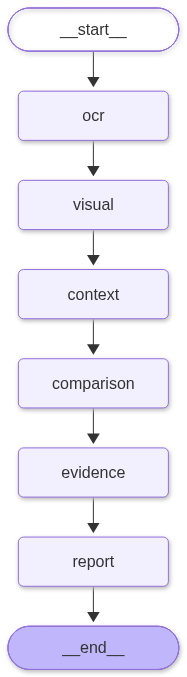

In [101]:
from IPython.display import display, Image

display(
    Image(investigation_app.get_graph().draw_mermaid_png())
)

In [103]:
from PIL import Image as PILImage

print("PIL Image loaded successfully:", hasattr(PILImage, "open"))

PIL Image loaded successfully: True


In [104]:
def visual_forensic_agent(image_path):

    image_path = Path(image_path)

    # 1. Load image using PIL
    image = PILImage.open(image_path).convert("RGB")

    # 2. MobileNetV2 classification
    resized = image.resize((224, 224))

    image_array = np.array(resized, dtype=np.float32)
    input_array = np.expand_dims(image_array, axis=0)

    classification_score = float(
        model.predict(input_array, verbose=0)[0][0]
    )

    classification = (
        "Potentially Tampered"
        if classification_score >= best_threshold
        else "Likely Authentic"
    )

    # 3. YOLOv8 region detection
    detections = best_model.predict(
        source=str(image_path),
        conf=0.25,
        verbose=False
    )

    regions = []

    for detection in detections:
        for box in detection.boxes:

            regions.append({
                "coordinates": box.xyxy[0].cpu().tolist(),
                "confidence": float(box.conf[0].cpu()),
                "class": int(box.cls[0].cpu())
            })

    return {
        "document": image_path.name,
        "classification": classification,
        "tampering_score": classification_score,
        "threshold": best_threshold,
        "detected_regions": regions,
        "number_of_suspicious_regions": len(regions)
    }

print("Visual Forensic Agent updated successfully!")

Visual Forensic Agent updated successfully!


In [105]:
final_result = investigation_app.invoke(initial_state)

print("Investigation Status:",
      final_result["investigation_status"])

print("Document:",
      final_result["final_report"]["document"])

print("Total Evidence:",
      final_result["evidence_result"]["total_evidence_items"])

Investigation Status: Completed
Document: kriyam_0218_C2.png
Total Evidence: 10


In [106]:
print(json.dumps(
    final_result["final_report"],
    indent=4
))

{
    "report_title": "Intelligent Document Forensics Investigation Report",
    "generated_at": "2026-11-07 20:04:47",
    "document": "kriyam_0218_C2.png",
    "executive_summary": {
        "total_evidence_items": 10,
        "investigation_status": "Requires Human Review",
        "classification": "Potentially Tampered"
    },
    "visual_and_document_evidence": [
        {
            "evidence_id": "EVIDENCE_1",
            "document": "kriyam_0218_C2.png",
            "page": 1,
            "evidence_type": "Potentially suspicious visual region",
            "bounding_box": [
                730.0272827148438,
                341.33819580078125,
                999.7020263671875,
                493.56207275390625
            ],
            "detection_confidence": 0.7994643449783325,
            "related_text": []
        },
        {
            "evidence_id": "EVIDENCE_2",
            "document": "kriyam_0218_C2.png",
            "page": 1,
            "evidence_type": "Poten

In [107]:
output_path = "/kaggle/working/outputs/complete_investigation.json"

with open(output_path, "w") as f:
    json.dump(final_result, f, indent=4, default=str)

print("Complete investigation saved:", output_path)

Complete investigation saved: /kaggle/working/outputs/complete_investigation.json


In [108]:
import os
import zipfile

base = "/kaggle/working"

files_to_download = [
    "document_forensics_model.keras",
    "model_config.json",
    "runs/document_tampering_detection/weights/best.pt",
    "ocr_results/extracted_documents.json",
    "cross_document_results.json",
    "outputs/contextual_analysis_fast.json",
    "outputs/final_investigation_report.json",
    "outputs/investigation_report.pdf"
]

zip_path = f"{base}/fastapi_model_files.zip"

with zipfile.ZipFile(zip_path, "w") as zipf:
    for file in files_to_download:
        full_path = os.path.join(base, file)

        if os.path.exists(full_path):
            zipf.write(full_path, arcname=os.path.basename(file))
            print("Added:", file)
        else:
            print("Not found:", file)

print("\nZIP created:", zip_path)

Added: document_forensics_model.keras
Added: model_config.json
Not found: runs/document_tampering_detection/weights/best.pt
Added: ocr_results/extracted_documents.json
Added: cross_document_results.json
Added: outputs/contextual_analysis_fast.json
Added: outputs/final_investigation_report.json
Added: outputs/investigation_report.pdf

ZIP created: /kaggle/working/fastapi_model_files.zip


In [109]:
from IPython.display import FileLink, display

display(FileLink("/kaggle/working/fastapi_model_files.zip"))

/kaggle/working/fastapi_model_files.zip